# 04 · Feature Engineering
**CRISP-DM Phase 3 — Data Preparation**

Scope:

| # | Step | Decision it finalizes |
|---|---|---|
| 1 | Confirm the label | 1D horizon, θ = 1% (recommended in `03_eda.ipynb`, item 11) |
| 2 | Chronological train/validation/test split | Purge the boundary rows so the forward-looking label never leaks across a split |
| 3 | Engineer features | Lagged returns, volatility (rolling std + ATR), volume signal, taker-buy ratio |
| 4 | Persist | Write model-ready `data/processed/*.parquet` for the modeling phase |

> ⚠️ **Leakage rules carried over from EDA item 11:** every feature for row *t* uses data up to and including `close[t]` only (see `src/features/returns.py`), and the label at *t* looks forward to `close[t + horizon]`. The split must stay chronological — never shuffled — and the boundary rows must be purged (see `chronological_split` below).

In [1]:
import sys
from pathlib import Path

# Make `src` importable whether the notebook runs from notebooks/ or the project root.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config
from src.features.engineering import (FLAT_THRESHOLD, LABEL_HORIZON, build_features,
                                      chronological_split)
from src.features.returns import DOWN, FLAT, UP
from src.visualization.style import BLUE, CLASS_COLORS, DIVERGING, apply_style, save

apply_style()

raw_1d = pd.read_parquet(config.INTERIM_DIR / f"{config.SYMBOL.lower()}_1D_clean.parquet")
print(f"{len(raw_1d):,} daily candles, {raw_1d.index.min().date()} -> {raw_1d.index.max().date()}")

3,332 daily candles, 2017-08-17 -> 2026-09-30


## 1 · Build the feature matrix and confirm the label

`build_features` engineers the feature set and attaches the label in one pass, then drops any row
with a NaN feature or label (the warm-up window for the longest rolling feature, and the last
`LABEL_HORIZON` rows which have no future candle yet).

In [3]:
features = build_features(raw_1d, horizon=LABEL_HORIZON, flat_threshold=FLAT_THRESHOLD)
print(f"label: 1D horizon, theta = {FLAT_THRESHOLD:.0%}")
print(f"{len(features):,} model-ready rows "
      f"({len(raw_1d) - len(features)} dropped to warm-up / trailing horizon)")
features.head()

label: 1D horizon, theta = 1%
2,983 model-ready rows (349 dropped to warm-up / trailing horizon)


,ret_lag1,ret_lag2,ret_lag3,ret_lag5,ret_lag7,ret_lag14,vol_7d,vol_14d,vol_30d,atr_14,log_volume,volume_z,taker_buy_ratio,label
open_time,,,,,,,,,,,,,,
2017-10-07 00:00:00+00:00,0.012284,0.029965,0.049691,0.009769,0.010110,0.157094,0.016656,0.032824,0.062326,0.051239,5.699097,-2.267007,0.488287,1.0
2017-10-08 00:00:00+00:00,0.047896,0.060180,0.077861,0.073776,0.058013,0.237246,0.024126,0.031626,0.060611,0.049886,6.252794,-0.756709,0.540242,1.0
2017-10-09 00:00:00+00:00,0.031179,0.079075,0.091359,0.128766,0.088845,0.199611,0.025224,0.028302,0.060809,0.048560,6.473062,-0.172215,0.542578,0.0
2017-10-10 00:00:00+00:00,-0.000813,0.030366,0.078262,0.108228,0.104143,0.208640,0.022866,0.027810,0.060468,0.050877,6.951027,0.909643,0.650708,0.0
2017-10-11 00:00:00+00:00,0.007990,0.007177,0.038356,0.098536,0.135943,0.139654,0.016038,0.021319,0.060415,0.047427,6.625962,0.059978,0.716840,1.0


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


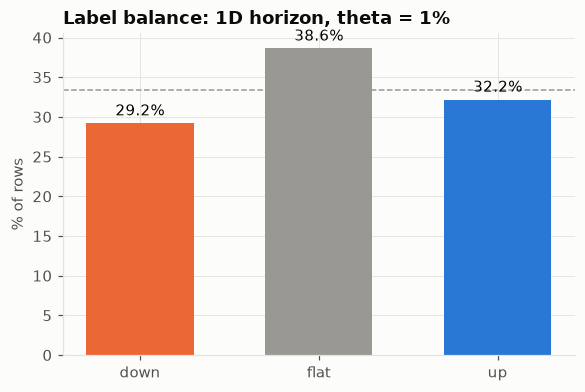

In [4]:
shares = features["label"].value_counts(normalize=True).rename({DOWN: "down", FLAT: "flat", UP: "up"})
shares = shares.reindex(["down", "flat", "up"])

fig, ax = plt.subplots(figsize=(6, 3.8))
ax.bar(shares.index, 100 * shares.values, color=[CLASS_COLORS[c] for c in shares.index], width=0.6)
ax.axhline(100 / 3, color="#9a9893", linestyle="--", linewidth=1)
ax.set(title="Label balance: 1D horizon, theta = 1%", ylabel="% of rows")
for x, v in enumerate(shares.values):
    ax.text(x, 100 * v + 1, f"{100 * v:.1f}%", ha="center")
save(fig, "04_label_balance")
plt.show()

**Check:** this should closely match the ~30 / 38 / 33 (down/flat/up) balance reported for 1D, θ=1% in
EDA item 11 — small differences come from the feature warm-up window trimming the start of the series.

## 2 · Chronological train / validation / test split

A 70/15/15 split by time, never shuffled. `embargo=LABEL_HORIZON` drops the last row(s) of `train` and
`val` whose label would otherwise be computed from a close price that falls inside the next split.

In [5]:
train, val, test = chronological_split(features, train_frac=0.7, val_frac=0.15, embargo=LABEL_HORIZON)

summary = pd.DataFrame({
    split: {"rows": len(df), "start": df.index.min().date(), "end": df.index.max().date()}
    for split, df in [("train", train), ("val", val), ("test", test)]
}).T
summary

,rows,start,end
train,2087,2017-10-07,2024-04-16
val,446,2024-04-18,2025-07-07
test,448,2025-07-09,2026-09-29


In [6]:
assert train.index.max() < val.index.min() < val.index.max() < test.index.min(), "splits must not overlap"
assert len(train) + len(val) + len(test) == len(features) - 2 * LABEL_HORIZON
print("OK: chronological, non-overlapping, boundary rows purged.")

OK: chronological, non-overlapping, boundary rows purged.


## 3 · Feature overview

A quick sanity check before handing this to modeling: the features should be mutually distinct
(not duplicates of each other) and have no leftover NaNs or infinities.

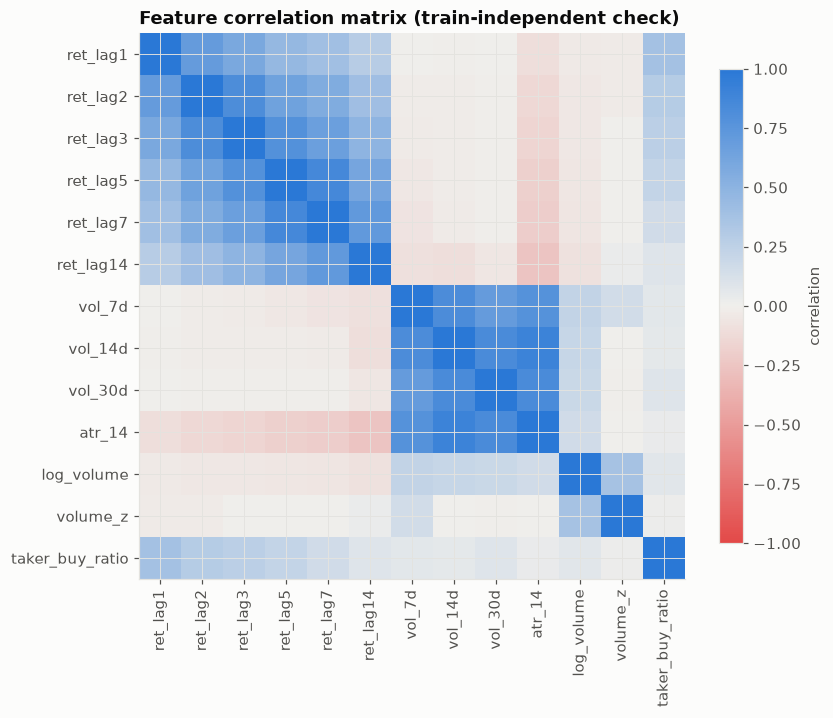

In [7]:
feature_cols = [c for c in features.columns if c != "label"]
assert np.isfinite(features[feature_cols].to_numpy()).all(), "no NaN/inf allowed in model-ready features"

corr = features[feature_cols].corr()
fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_cols)), feature_cols, rotation=90)
ax.set_yticks(range(len(feature_cols)), feature_cols)
ax.set_title("Feature correlation matrix (train-independent check)")
fig.colorbar(im, ax=ax, shrink=0.8, label="correlation")
save(fig, "04_feature_correlation")
plt.show()

## 4 · Persist model-ready data

Written to `data/processed/` (gitignored, regenerated by this notebook) for the modeling phase.

In [8]:
config.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
for split, df in [("train", train), ("val", val), ("test", test)]:
    path = config.PROCESSED_DIR / f"{config.SYMBOL.lower()}_1D_{split}.parquet"
    df.to_parquet(path)
    print(f"saved {path.relative_to(ROOT)}  ({len(df):,} rows)")

saved data\processed\btcusdt_1D_train.parquet  (2,087 rows)
saved data\processed\btcusdt_1D_val.parquet  (446 rows)
saved data\processed\btcusdt_1D_test.parquet  (448 rows)


## Summary -> inputs for Modeling

| Decision | Value |
|---|---|
| Label | 1D horizon, θ = 1% (UP / FLAT / DOWN) |
| Split | Chronological 70/15/15, embargo = 1 row at each boundary |
| Features | 6 lagged returns (1-14d), 3 rolling volatilities (7/14/30d), ATR(14)/close, log volume, 14d volume z-score, taker-buy ratio |
| Output | `data/processed/btcusdt_1D_{train,val,test}.parquet` |

Next phase (Modeling): train a classifier on `train`, tune on `val`, and hold `test` untouched until
the final evaluation against the baselines from `03_eda.ipynb` (majority, persistence, buy-and-hold).